# E-commerce Sales & Customer Intelligence

**Company:** NovaCart Retail (fictional)  
**Data:** Synthetic portfolio dataset generated for demonstration.  
**Tools:** Python, pandas, matplotlib, SQLite/SQL, Power BI-ready CSVs.

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
data = {name: pd.read_csv(ROOT / "data" / f"{name}.csv") for name in
        ["customers","products","sellers","orders","order_items","payments","reviews"]}
orders, items, products, customers = data["orders"], data["order_items"], data["products"], data["customers"]
orders["order_date"] = pd.to_datetime(orders["order_date"])
items = items.merge(products[["product_id","category"]], on="product_id")
items = items.merge(orders[["order_id","customer_id","order_date","order_status"]], on="order_id")


## 1. Data quality checks

In [16]:
for name, df in data.items():
    print(name, df.shape, "duplicate rows:", df.duplicated().sum())
    print(df.isna().sum().to_dict())


customers (1200, 4) duplicate rows: 0
{'customer_id': 0, 'state': 0, 'customer_since': 0, 'region': 0}
products (180, 4) duplicate rows: 0
{'product_id': 0, 'category': 0, 'unit_cost': 0, 'list_price': 0}
sellers (65, 2) duplicate rows: 0
{'seller_id': 0, 'state': 0}
orders (6500, 8) duplicate rows: 0
{'order_id': 0, 'customer_id': 0, 'seller_id': 0, 'order_date': 0, 'order_status': 0, 'delivery_days': 815, 'estimated_delivery_days': 0, 'delivered_on_time': 815}
order_items (9399, 9) duplicate rows: 0
{'order_id': 0, 'product_id': 0, 'quantity': 0, 'unit_price': 0, 'freight_value': 0, 'unit_cost': 0, 'gross_revenue': 0, 'product_cost': 0, 'gross_profit': 0}
payments (6500, 4) duplicate rows: 0
{'order_id': 0, 'payment_method': 0, 'payment_value': 0, 'installments': 0}
reviews (6500, 3) duplicate rows: 0
{'order_id': 0, 'review_score': 0, 'review_date': 0}


## 2. Executive KPIs

In [17]:
delivered = orders[orders.order_status == "delivered"]
delivered_items = items[items.order_id.isin(delivered.order_id)]
revenue = delivered_items.gross_revenue.sum()
profit = delivered_items.gross_profit.sum()
kpis = pd.Series({
    "Delivered orders": delivered.order_id.nunique(),
    "Gross revenue": revenue,
    "Gross profit*": profit,
    "Average order value": revenue / delivered.order_id.nunique(),
    "On-time delivery %": delivered.delivered_on_time.mean()*100,
    "Average delivery days": delivered.delivery_days.mean()
})
display(kpis)


Delivered orders         5.685000e+03
Gross revenue            4.458321e+06
Gross profit*            2.059056e+06
Average order value      7.842253e+02
On-time delivery %       6.678980e+01
Average delivery days    8.096042e+00
dtype: float64

## 3. Monthly sales trend

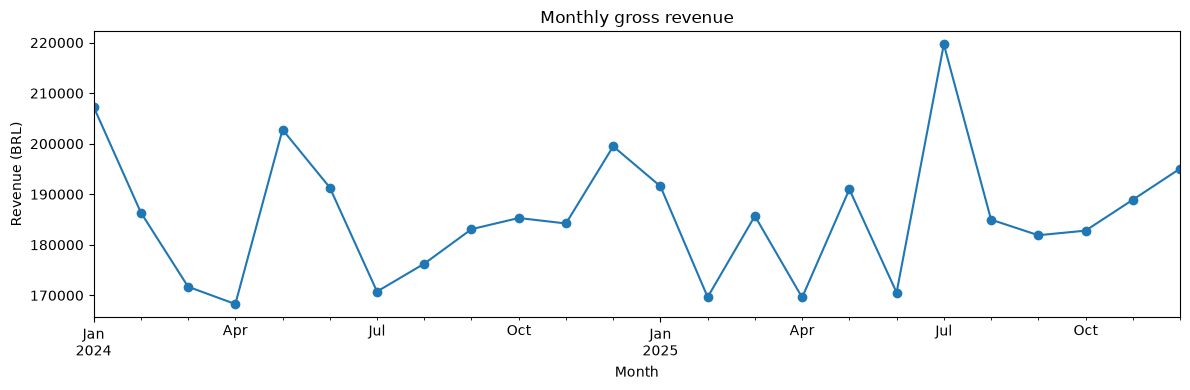

In [18]:
monthly = delivered_items.groupby(delivered_items.order_date.dt.to_period("M")).gross_revenue.sum()
monthly.plot(figsize=(12,4), marker="o", title="Monthly gross revenue")
plt.ylabel("Revenue (BRL)"); plt.xlabel("Month"); plt.tight_layout(); plt.show()


## 4. Category profitability

,revenue,profit,margin_pct
category,,,
beauty,838739.51,395470.71,47.15
sports,656699.02,310394.07,47.27
automotive,628438.87,261645.71,41.63
home_and_garden,572798.19,316135.41,55.19
books,526946.92,282361.29,53.58
fashion,479142.64,211206.77,44.08
toys,443436.45,150452.72,33.93
electronics,312119.45,131389.08,42.10


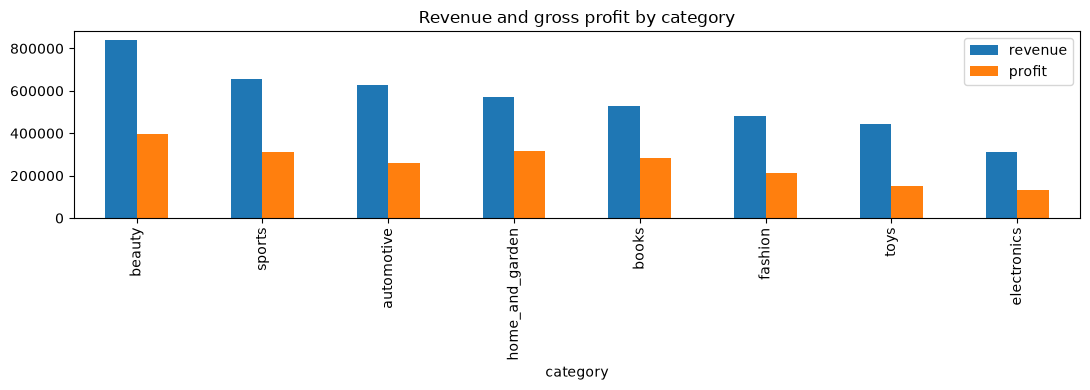

In [19]:
category = delivered_items.groupby("category").agg(
    revenue=("gross_revenue","sum"), profit=("gross_profit","sum")).sort_values("revenue",ascending=False)
category["margin_pct"] = 100*category.profit/category.revenue
display(category.round(2))
category[["revenue","profit"]].plot(kind="bar",figsize=(11,4),title="Revenue and gross profit by category")
plt.tight_layout(); plt.show()


## 5. Customer repeat purchase analysis

In [20]:
customer_orders = delivered.groupby("customer_id").order_id.nunique()
repeat_rate = (customer_orders > 1).mean()*100
print(f"Repeat-customer rate among customers with delivered orders: {repeat_rate:.2f}%")


Repeat-customer rate among customers with delivered orders: 96.05%


## 6. Delivery and review relationship

In [21]:
delivery_reviews = delivered.merge(data["reviews"], on="order_id")
delivery_reviews["delivery_group"] = np.where(
    delivery_reviews.delivered_on_time.eq(1),"On time","Late")
display(delivery_reviews.groupby("delivery_group").review_score.agg(["count","mean"]).round(2))


,count,mean
delivery_group,,
Late,1888,4.00
On time,3797,3.98


## 7. Interpretation notes

- Treat item-level gross profit as an indicative contribution measure, not audited net profit.
- The dataset is synthetic and is intended to demonstrate analytics workflow, not to make claims about a real retailer.
- Customer repeat rate is calculated among customers with at least one delivered order in the available period.